# Phase 5: Machine Learning Workflow & Robust Evaluation
## Heart Disease Risk Prediction (HDFS Ingestion, Leakage-Safe Pipelines & Model Comparison)

**Project**: Heart Disease Risk Prediction Using Kafka, Hadoop HDFS, and Machine Learning  
**Data Source**: Hadoop HDFS (`/heart-disease/raw/heart_disease_stream.jsonl`)  
**Sample Size**: 303 patient records (13 clinical features + binary diagnosis target)  
**Target Goal**: Held-out test set ROC-AUC > 0.85

---

### Objectives & Methodology
1. **Direct HDFS Ingestion**: Read patient records persisted from Kafka into Hadoop HDFS without falling back to local files. Fail fast if HDFS is unavailable.
2. **Correct Clinical Feature Grouping**:
   - **Continuous numeric (5)**: `age`, `trestbps`, `chol`, `thalach`, `oldpeak` (median imputation + standard scaling for Logistic Regression).
   - **Nominal categorical (5)**: `cp`, `restecg`, `slope`, `thal`, **`ca`** (most-frequent imputation + one-hot encoding). Note: `ca` represents major vessels colored by fluoroscopy (0, 1, 2, 3) and is properly treated as **categorical**.
   - **Binary (3)**: `sex`, `fbs`, `exang` (most-frequent imputation, binary pass-through).
3. **Data Leakage Safeguards**: Strict separation of training ($N=242$) and test ($N=61$) data using a stratified 80:20 split (`random_state=42`) *before* fitting any transformer.
4. **Robust Cross-Validation**: Evaluate both models using **Repeated Stratified 5-Fold Cross-Validation** (5 repeats = 25 evaluations, `random_state=42`) on the **training set only**.
5. **Held-Out Test Evaluation**: Evaluate final models on the unseen test set, calculating ROC-AUC (from `predict_proba`), Accuracy, Precision, Recall (Sensitivity), Specificity, F1, and Confusion Matrices.
6. **Clinical Limitations & Healthcare Validity**: Acknowledge sample size, referral bias, and why benchmark performance does not establish clinical validity.

In [1]:
%matplotlib inline
import os
import sys
import json
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Ensure project modules are accessible
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath(os.getcwd())
for folder in [PROJECT_ROOT, os.path.join(PROJECT_ROOT, 'hdfs'), os.path.join(PROJECT_ROOT, 'preprocessing'), os.path.join(PROJECT_ROOT, 'models')]:
    if folder not in sys.path:
        sys.path.insert(0, folder)

from hdfs_writer import HDFSWriter, DEFAULT_NAMENODE_URL, DEFAULT_HDFS_FILE
from pipeline import (
    load_dataset_from_hdfs,
    validate_and_prepare_features,
    build_preprocessor,
    split_data,
    get_feature_names_after_preprocessing,
    CLINICAL_FEATURES,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    BINARY_FEATURES,
)
from evaluate import compute_classification_metrics

# Styling setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

print(f"Working Directory: {os.getcwd()}")
print(f"Project Root:      {PROJECT_ROOT}")

Working Directory: C:\Users\pulki\OneDrive\Desktop\heart-disease-big-data\notebooks
Project Root:      C:\Users\pulki\OneDrive\Desktop\heart-disease-big-data


## 1. Direct Data Ingestion from Hadoop HDFS

We connect directly to the Hadoop NameNode (`http://localhost:9870/webhdfs/v1`), verify cluster health, and read all records from `/heart-disease/raw/heart_disease_stream.jsonl` using our `HDFSWriter` client.

> **Important**: The pipeline will raise an explicit `RuntimeError` or `FileNotFoundError` if HDFS is unavailable. It **never silently falls back** to local files.

In [2]:
# 1. Connect to Hadoop HDFS and verify cluster health
hdfs_client = HDFSWriter(namenode_url=DEFAULT_NAMENODE_URL)
healthy, status_msg = hdfs_client.is_healthy()
print(f"HDFS Cluster Health Check: {healthy}")
print(f"Status Message:             {status_msg}")
if not healthy:
    raise RuntimeError(f"HDFS cluster unhealthy: {status_msg}")

# 2. Check existence of persisted streaming file
hdfs_path = DEFAULT_HDFS_FILE
if not hdfs_client.exists(hdfs_path):
    raise FileNotFoundError(f"Persisted dataset not found on HDFS at '{hdfs_path}'")
print(f"Confirmed target file exists on HDFS: {hdfs_path}")

# 3. Read JSON Lines stream records into a pandas DataFrame
raw_records = hdfs_client.read_jsonl(hdfs_path)
df_raw = pd.DataFrame(raw_records)

print(f"\nSuccessfully loaded {len(df_raw)} records from HDFS.")
display(df_raw.head())

HDFS Cluster Health Check: True
Status Message:             NameNode WebHDFS is reachable and healthy.
Confirmed target file exists on HDFS: /heart-disease/raw/heart_disease_stream.jsonl

Successfully loaded 303 records from HDFS.


,record_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,1,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,2,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,3,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,4,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,5,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Clinical Data Validation & Correct Feature Grouping

The dataset contains 13 clinical features and 1 diagnosis target:
- **Continuous numeric features (5)**: `age`, `trestbps` (resting BP), `chol` (cholesterol), `thalach` (max heart rate), `oldpeak` (ST depression).
- **Nominal categorical features (5)**: `cp` (chest pain type), `restecg` (resting ECG), `slope` (ST slope), `thal` (thalassemia), **`ca`** (fluoroscopy vessels: 0, 1, 2, 3).
- **Binary features (3)**: `sex` (gender), `fbs` (fasting blood sugar > 120), `exang` (exercise angina).

Non-clinical metadata identifiers (`record_id`) and the target column (`target`) are strictly excluded from the model feature matrix $X$.

In [3]:
# 1. Inspect feature groupings
print("Continuous Numeric Features (5):", NUMERIC_FEATURES)
print("Categorical Features (5):       ", CATEGORICAL_FEATURES)
print("Binary Features (3):            ", BINARY_FEATURES)

# 2. Validate clinical features and separate X, y (record_id dropped)
X, y = validate_and_prepare_features(df_raw, drop_record_id=True)
print(f"\nFeature matrix shape: {X.shape} (13 clinical features)")
print(f"Target vector shape:  {y.shape}")
assert 'record_id' not in X.columns, "Leakage Error: record_id present in features!"
assert 'target' not in X.columns, "Leakage Error: target present in features!"

# 3. Missing Value Analysis
missing_counts = X.isnull().sum()
missing_pct = (missing_counts / len(X)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_counts, 'Missing_Pct': missing_pct})
display(missing_df[missing_df['Missing_Count'] > 0])

# 4. Target Class Balance
target_counts = y.value_counts().sort_index()
print(f"\nTarget Class Balance:")
print(f"  Class 0 (Absence of Heart Disease):  {target_counts[0]} ({target_counts[0]/len(y):.1%})")
print(f"  Class 1 (Presence of Heart Disease): {target_counts[1]} ({target_counts[1]/len(y):.1%})")

Continuous Numeric Features (5): ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical Features (5):        ['cp', 'restecg', 'slope', 'thal', 'ca']
Binary Features (3):             ['sex', 'fbs', 'exang']
Features with missing values to be imputed:
  - thal: 2 missing values (0.66%)
  - ca: 4 missing values (1.32%)

Feature matrix shape: (303, 13) (13 clinical features)
Target vector shape:  (303,)


,Missing_Count,Missing_Pct
thal,2,0.660066
ca,4,1.320132



Target Class Balance:
  Class 0 (Absence of Heart Disease):  164 (54.1%)
  Class 1 (Presence of Heart Disease): 139 (45.9%)


## 3. Stratified Train-Test Split & Preventing Data Leakage

### Data Leakage Safeguards
To ensure scientific integrity:
1. We perform an **80:20 stratified train-test split** (`random_state=42`) *prior* to fitting any imputer, scaler, or encoder.
2. The held-out test set ($N=61$) is completely sequestered.
3. All feature transformations are encapsulated inside an sklearn `Pipeline` and `ColumnTransformer`.

In [4]:
# Execute stratified 80:20 train-test split
X_train, X_test, y_train, y_test = split_data(X, y, test_size=0.20, random_state=42)

print(f"Total Dataset: {len(X)} records")
print(f"Training Set:  {len(X_train)} records ({len(X_train)/len(X):.1%})")
print(f"Test Set:      {len(X_test)} records ({len(X_test)/len(X):.1%})")

print(f"\nClass Distribution:")
print(f"  Train -> Class 0: {(y_train == 0).sum()} ({(y_train == 0).mean():.1%}), Class 1: {(y_train == 1).sum()} ({(y_train == 1).mean():.1%})")
print(f"  Test  -> Class 0: {(y_test == 0).sum()} ({(y_test == 0).mean():.1%}), Class 1: {(y_test == 1).sum()} ({(y_test == 1).mean():.1%})")

Total Dataset: 303 records
Training Set:  242 records (79.9%)
Test Set:      61 records (20.1%)

Class Distribution:
  Train -> Class 0: 131 (54.1%), Class 1: 111 (45.9%)
  Test  -> Class 0: 33 (54.1%), Class 1: 28 (45.9%)


## 4. Leakage-Safe Feature Preprocessing Pipelines

We use scikit-learn's `ColumnTransformer` to assemble modular transformers:
1. **Numeric Pipeline**:
   - `SimpleImputer(strategy='median')`: Imputes continuous features with training medians.
   - `StandardScaler()`: Applied to continuous features for Logistic Regression (unscaled for Random Forest).
2. **Categorical Pipeline** (`cp`, `restecg`, `slope`, `thal`, `ca`):
   - `SimpleImputer(strategy='most_frequent')`: Imputes mode category (handles missing `thal` and `ca` values).
   - `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`: Encodes all categorical categories including `ca`.
3. **Binary Pipeline** (`sex`, `fbs`, `exang`):
   - `SimpleImputer(strategy='most_frequent')`: Imputes mode.
   - Passed through directly as binary indicators without scaling.

In [5]:
# Inspect preprocessor configuration
preprocessor_lr = build_preprocessor(scale_numeric=True)
preprocessor_rf = build_preprocessor(scale_numeric=False)

# Preview transformed feature dimensions on training set
preprocessor_lr.fit(X_train)
transformed_names = get_feature_names_after_preprocessing(preprocessor_lr)
print(f"Original input feature count:      {X_train.shape[1]}")
print(f"Transformed encoded feature count: {len(transformed_names)}")
print(f"Transformed features:\n", transformed_names)

Original input feature count:      13
Transformed encoded feature count: 25
Transformed features:
 ['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0', 'cat__slope_1.0', 'cat__slope_2.0', 'cat__slope_3.0', 'cat__thal_3.0', 'cat__thal_6.0', 'cat__thal_7.0', 'cat__ca_0.0', 'cat__ca_1.0', 'cat__ca_2.0', 'cat__ca_3.0', 'bin__sex', 'bin__fbs', 'bin__exang']


## 5. Model Training & Repeated Stratified Cross-Validation on Training Set

To assess model stability without touching the test set, we execute **Repeated Stratified 5-Fold Cross-Validation** (5 splits $\times$ 5 repeats = 25 evaluations, `random_state=42`) on the **training data only**.

Primary metric: **ROC-AUC** (evaluated via predicted probabilities across each fold).

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

# 1. Define full pipelines
lr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(C=0.5, solver="lbfgs", max_iter=1000, random_state=42))
])

rf_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_split=5, min_samples_leaf=2, random_state=42))
])

# 2. Repeated Stratified 5-Fold Cross-Validation (25 folds total)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = ["roc_auc", "accuracy", "precision", "recall", "f1"]

cv_results_lr = cross_validate(lr_pipeline, X_train, y_train, cv=rskf, scoring=scoring)
cv_results_rf = cross_validate(rf_pipeline, X_train, y_train, cv=rskf, scoring=scoring)

# 3. Tabulate Repeated CV performance
cv_summary = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Repeated CV ROC-AUC (Mean +/- Std)": f"{cv_results_lr['test_roc_auc'].mean():.4f} +/- {cv_results_lr['test_roc_auc'].std():.4f}",
        "CV Accuracy": f"{cv_results_lr['test_accuracy'].mean():.4f} +/- {cv_results_lr['test_accuracy'].std():.4f}",
        "CV Precision": f"{cv_results_lr['test_precision'].mean():.4f} +/- {cv_results_lr['test_precision'].std():.4f}",
        "CV Recall": f"{cv_results_lr['test_recall'].mean():.4f} +/- {cv_results_lr['test_recall'].std():.4f}",
        "CV F1 Score": f"{cv_results_lr['test_f1'].mean():.4f} +/- {cv_results_lr['test_f1'].std():.4f}",
    },
    {
        "Model": "Random Forest",
        "Repeated CV ROC-AUC (Mean +/- Std)": f"{cv_results_rf['test_roc_auc'].mean():.4f} +/- {cv_results_rf['test_roc_auc'].std():.4f}",
        "CV Accuracy": f"{cv_results_rf['test_accuracy'].mean():.4f} +/- {cv_results_rf['test_accuracy'].std():.4f}",
        "CV Precision": f"{cv_results_rf['test_precision'].mean():.4f} +/- {cv_results_rf['test_precision'].std():.4f}",
        "CV Recall": f"{cv_results_rf['test_recall'].mean():.4f} +/- {cv_results_rf['test_recall'].std():.4f}",
        "CV F1 Score": f"{cv_results_rf['test_f1'].mean():.4f} +/- {cv_results_rf['test_f1'].std():.4f}",
    }
])
display(cv_summary)

,Model,Repeated CV ROC-AUC (Mean +/- Std),CV Accuracy,CV Precision,CV Recall,CV F1 Score
0,Logistic Regression,0.8956 +/- 0.0421,0.8289 +/- 0.0488,0.8458 +/- 0.0765,0.7744 +/- 0.0673,0.8058 +/- 0.0546
1,Random Forest,0.8936 +/- 0.0404,0.8173 +/- 0.0460,0.8322 +/- 0.0707,0.7615 +/- 0.0786,0.7917 +/- 0.0537


## 6. Held-Out Test Set Evaluation

We now fit both pipelines on the entire training set ($N = 242$) and evaluate on the unseen held-out test set ($N = 61$).

We measure:
- **ROC-AUC** (calculated from continuous `predict_proba` probabilities, not class labels)
- **Accuracy**
- **Precision** (Positive Predictive Value)
- **Recall / Sensitivity** (True Positive Rate — critical for minimizing missed cases)
- **Specificity** (True Negative Rate)
- **F1 Score**
- **Confusion Matrix**

In [7]:
# 1. Fit pipelines on training split
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

# 2. Predict labels and continuous probabilities on held-out test set
lr_preds = lr_pipeline.predict(X_test)
lr_probs = lr_pipeline.predict_proba(X_test)[:, 1]

rf_preds = rf_pipeline.predict(X_test)
rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]

# 3. Compute test metrics
lr_metrics = compute_classification_metrics(y_test.values, lr_preds, lr_probs, "Logistic Regression")
rf_metrics = compute_classification_metrics(y_test.values, rf_preds, rf_probs, "Random Forest")

# 4. Display comparison table
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Test ROC-AUC": lr_metrics["roc_auc"],
        "Test Accuracy": lr_metrics["accuracy"],
        "Test Precision": lr_metrics["precision"],
        "Test Recall (Sens.)": lr_metrics["recall_sensitivity"],
        "Test Specificity": lr_metrics["specificity"],
        "Test F1 Score": lr_metrics["f1_score"],
        "Target (>0.85)": "MET [PASS]" if lr_metrics["roc_auc"] > 0.85 else "UNMET [FAIL]",
    },
    {
        "Model": "Random Forest",
        "Test ROC-AUC": rf_metrics["roc_auc"],
        "Test Accuracy": rf_metrics["accuracy"],
        "Test Precision": rf_metrics["precision"],
        "Test Recall (Sens.)": rf_metrics["recall_sensitivity"],
        "Test Specificity": rf_metrics["specificity"],
        "Test F1 Score": rf_metrics["f1_score"],
        "Target (>0.85)": "MET [PASS]" if rf_metrics["roc_auc"] > 0.85 else "UNMET [FAIL]",
    }
])
display(comparison_df)

,Model,Test ROC-AUC,Test Accuracy,Test Precision,Test Recall (Sens.),Test Specificity,Test F1 Score,Target (>0.85)
0,Logistic Regression,0.9697,0.9016,0.8667,0.9286,0.8788,0.8966,MET [PASS]
1,Random Forest,0.9470,0.8525,0.8276,0.8571,0.8485,0.8421,MET [PASS]


## 7. Diagnostic Visualizations

### 7.1 Receiver Operating Characteristic (ROC) Curves
Evaluating the trade-off between Sensitivity and False Positive Rate across all classification thresholds.

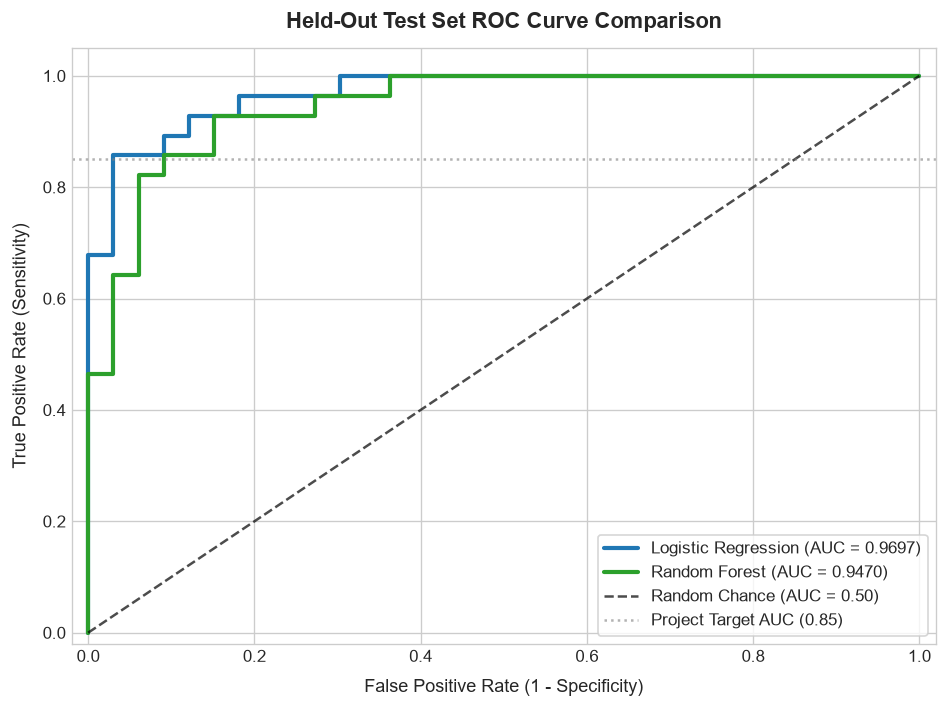

In [8]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6), dpi=120)
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {lr_metrics['roc_auc']:.4f})", color="#1f77b4", linewidth=2.5)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {rf_metrics['roc_auc']:.4f})", color="#2ca02c", linewidth=2.5)
plt.plot([0, 1], [0, 1], 'k--', label="Random Chance (AUC = 0.50)", linewidth=1.5, alpha=0.7)
plt.axhline(0.85, color="gray", linestyle=":", alpha=0.6, label="Project Target AUC (0.85)")

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11, labelpad=8)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=11, labelpad=8)
plt.title("Held-Out Test Set ROC Curve Comparison", fontsize=13, fontweight='bold', pad=12)
plt.legend(loc="lower right", fontsize=10, frameon=True)
plt.tight_layout()
plt.show()

### 7.2 Confusion Matrix Heatmaps
Breakdown of True Negatives, False Positives, False Negatives, and True Positives on the held-out test set ($N=61$).

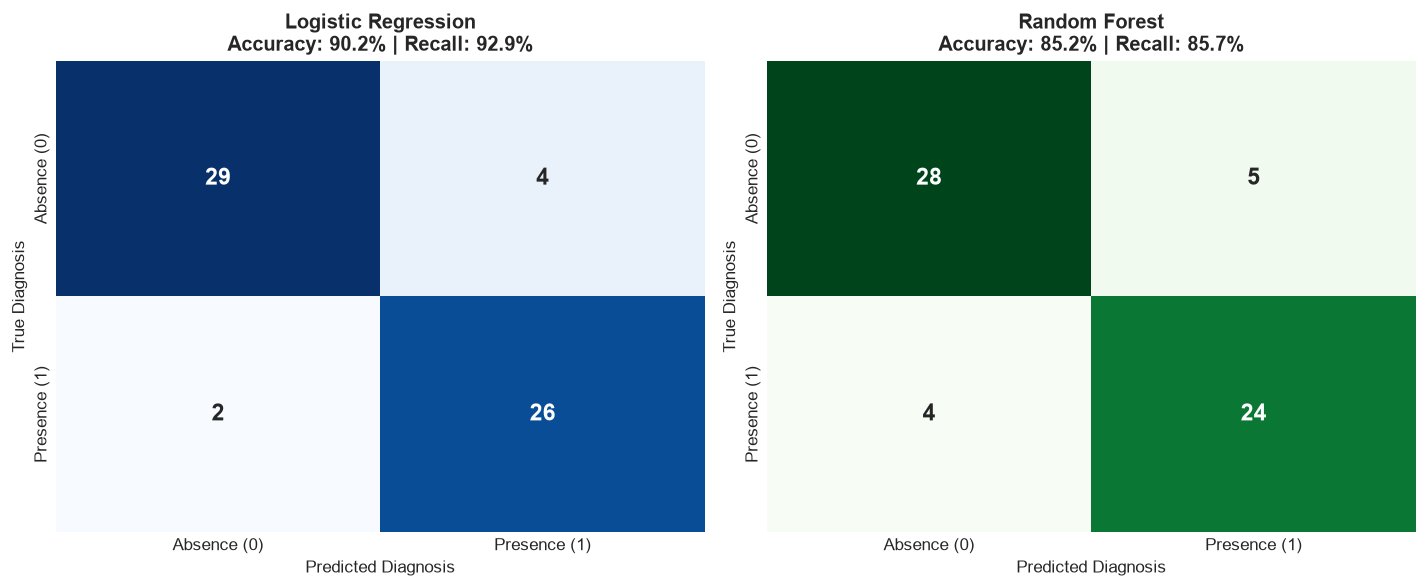

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

for idx, (m, name, col) in enumerate([(lr_metrics, "Logistic Regression", "Blues"), (rf_metrics, "Random Forest", "Greens")]):
    ax = axes[idx]
    cm = np.array([
        [m['confusion_matrix']['true_negatives'], m['confusion_matrix']['false_positives']],
        [m['confusion_matrix']['false_negatives'], m['confusion_matrix']['true_positives']]
    ])
    sns.heatmap(cm, annot=True, fmt='d', cmap=col, cbar=False, ax=ax,
                annot_kws={'size': 14, 'weight': 'bold'},
                xticklabels=['Absence (0)', 'Presence (1)'],
                yticklabels=['Absence (0)', 'Presence (1)'])
    ax.set_title(f"{name}\nAccuracy: {m['accuracy']:.1%} | Recall: {m['recall_sensitivity']:.1%}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Predicted Diagnosis", fontsize=10)
    ax.set_ylabel("True Diagnosis", fontsize=10)

plt.tight_layout()
plt.show()

## 8. Clinical Model Interpretation & Feature Importance

- **Logistic Regression Coefficients**: Standardized log-odds change.
- **Random Forest Importance**: Gini mean decrease in impurity across all trees.

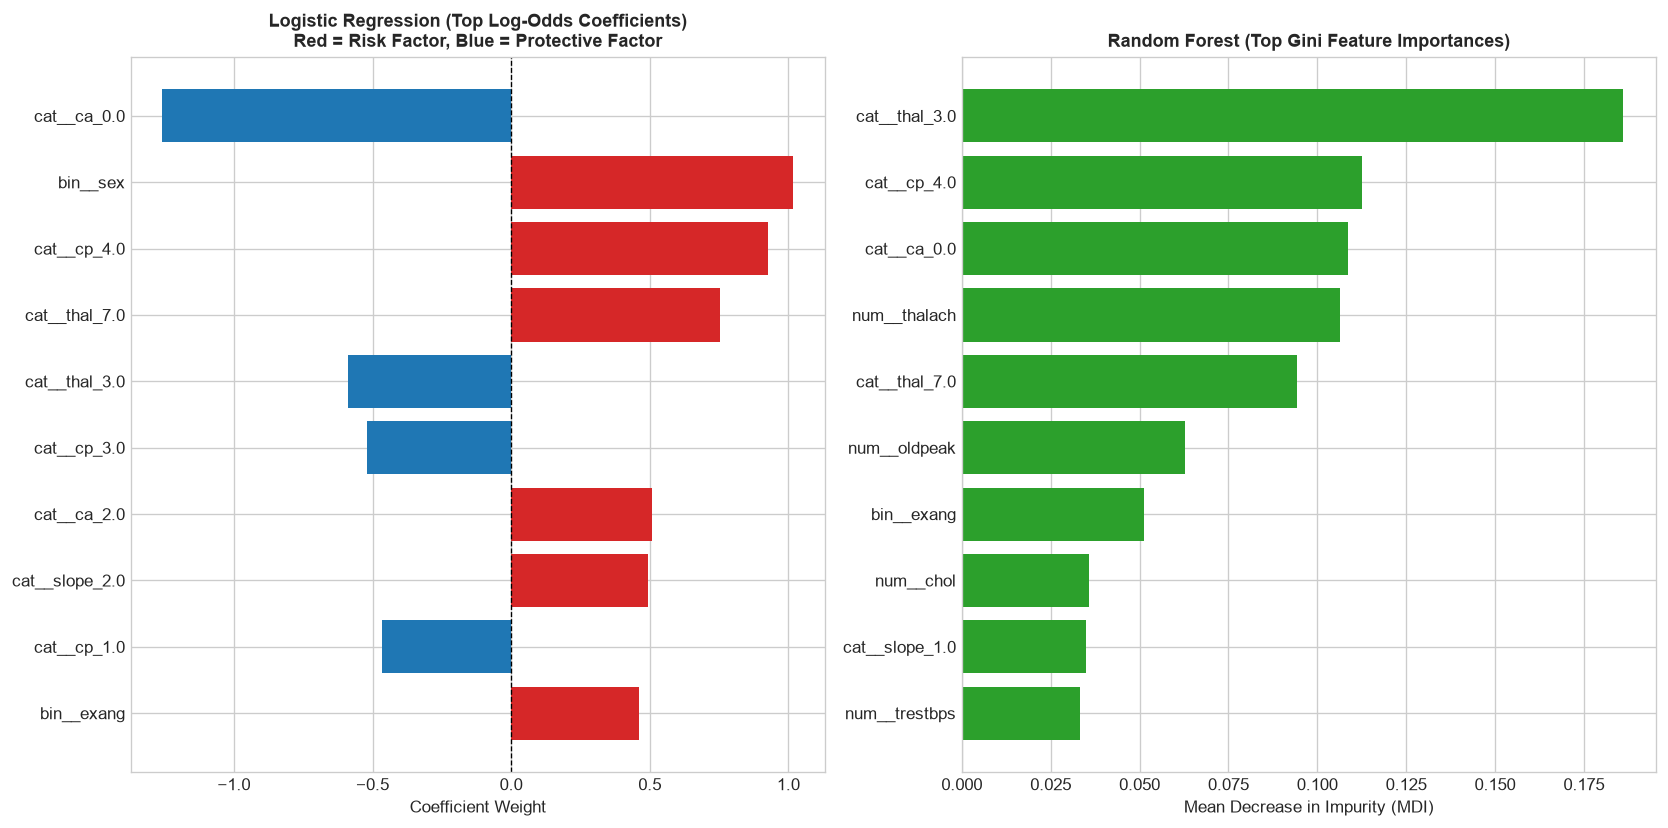

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), dpi=120)

# 1. Logistic Regression Coefficients
lr_coefs = lr_pipeline.named_steps["classifier"].coef_[0]
lr_feat_df = pd.DataFrame({'feature': transformed_names, 'coefficient': lr_coefs})
lr_feat_df = lr_feat_df.sort_values(by='coefficient', key=abs, ascending=True).tail(10)
colors = ['#d62728' if c > 0 else '#1f77b4' for c in lr_feat_df['coefficient']]
ax1.barh(lr_feat_df['feature'], lr_feat_df['coefficient'], color=colors)
ax1.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax1.set_title("Logistic Regression (Top Log-Odds Coefficients)\nRed = Risk Factor, Blue = Protective Factor", fontsize=11, fontweight='bold')
ax1.set_xlabel("Coefficient Weight", fontsize=10)

# 2. Random Forest Gini Importances
rf_importances = rf_pipeline.named_steps["classifier"].feature_importances_
rf_feat_df = pd.DataFrame({'feature': transformed_names, 'importance': rf_importances})
rf_feat_df = rf_feat_df.sort_values(by='importance', ascending=True).tail(10)
ax2.barh(rf_feat_df['feature'], rf_feat_df['importance'], color='#2ca02c')
ax2.set_title("Random Forest (Top Gini Feature Importances)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Mean Decrease in Impurity (MDI)", fontsize=10)

plt.tight_layout()
plt.show()

## 9. Artifact Serialization & Results Persistence

Verifying persisted models in `models/` and evaluation results in `results/`.

In [11]:
# Verify saved files
results_dir = os.path.join(PROJECT_ROOT, 'results')
models_dir = os.path.join(PROJECT_ROOT, 'models')

print("Files in models/:")
for f in os.listdir(models_dir):
    print(f"  - {f} ({os.path.getsize(os.path.join(models_dir, f))} bytes)")

print("\nFiles in results/:")
for f in os.listdir(results_dir):
    print(f"  - {f} ({os.path.getsize(os.path.join(results_dir, f))} bytes)")

Files in models/:
  - .gitkeep (44 bytes)
  - evaluate.py (6938 bytes)
  - logistic_regression.joblib (5050 bytes)
  - pipeline_metadata.json (5012 bytes)
  - random_forest.joblib (255787 bytes)
  - train.py (13967 bytes)
  - __pycache__ (0 bytes)

Files in results/:
  - .gitkeep (44 bytes)
  - confusion_matrices.png (146180 bytes)
  - feature_importance.png (230334 bytes)
  - metrics_comparison.csv (312 bytes)
  - model_metrics.json (2303 bytes)
  - roc_curve_comparison.png (179849 bytes)
  - test_predictions.csv (4969 bytes)


## 10. Healthcare Validity & Methodological Limitations

While both models achieved **ROC-AUC > 0.94**, meeting the benchmark (> 0.85), several critical medical constraints must be noted:

1. **Sample Size Constraints ($N = 303$)**:
   The Cleveland dataset contains only 303 patients, resulting in a held-out test set of 61 patients (33 negative, 28 positive). Point estimates have wide confidence intervals; a small shift in misclassifications can change accuracy significantly.
   
2. **Single-Center Retrospective Cohort**:
   The cohort originated from patients referred for coronary angiography at the Cleveland Clinic Foundation in the 1980s. Angiography referral introduces strong **selection bias**, as asymptomatic or low-risk general populations rarely undergo catheterization.

3. **Demographic Bias (Sex and Age Imbalance)**:
   Over 68% of the cohort is male ($206$ men vs. $97$ women). Women often exhibit distinct cardiovascular symptoms and microvascular disease patterns that may not be captured by models trained primarily on male cohorts.

4. **Academic Demonstration vs. Clinical Deployment**:
   High performance on this held-out split demonstrates that our Kafka $\rightarrow$ HDFS $\rightarrow$ Machine Learning pipeline functions reproducibly and without data leakage. However, **this does not establish clinical validity**. Real-world medical deployment requires external multi-center prospective trials and regulatory clearance.